# TASK 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_style("whitegrid")

In [3]:
import os
os.getcwd()

'C:\\Users\\riths\\OneDrive\\Desktop\\Weekly Task'

In [4]:
df = pd.read_csv(r"C:\\Users\\riths\\OneDrive\\Desktop\\Weekly Task\StudentsPerformance.csv")
print("Data uploaded successfully")

Data uploaded successfully


In [5]:
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [6]:
df = pd.read_csv("StudentsPerformance.csv")

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
# Dataset Dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1000
Columns: 8


In [8]:
# Column names
print(df.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [9]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [10]:
# Last 5 records
df.tail()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [11]:
# Statistical summary
df.describe(include="all")

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [12]:
missing_values = df.isnull().sum()

print(missing_values)

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [13]:
# Percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary


,Missing Count,Missing Percentage
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


In [14]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [15]:
# Numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [16]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)


Number of duplicate records: 0


In [17]:
df[df.duplicated()]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score


In [18]:
# Remove duplicates
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1000, 8)


In [19]:
categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())



 gender
gender
female    518
male      482
Name: count, dtype: int64

 race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

 parental level of education
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

 lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

 test preparation course
test preparation course
none         642
completed    358
Name: count, dtype: int64


In [20]:
for col in categorical_columns:
    print(col, ":", df[col].unique())


gender : ['female' 'male']
race/ethnicity : ['group B' 'group C' 'group A' 'group D' 'group E']
parental level of education : ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
lunch : ['standard' 'free/reduced']
test preparation course : ['none' 'completed']


In [21]:
for col in categorical_columns:
    df[col] = df[col].str.strip()


In [22]:
for col in categorical_columns:
    df[col] = df[col].astype("category")

In [23]:
df.dtypes


gender                         category
race/ethnicity                 category
parental level of education    category
lunch                          category
test preparation course        category
math score                        int64
reading score                     int64
writing score                     int64
dtype: object

In [24]:
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

In [25]:
mean_scores = df[score_columns].mean()

print("Mean Scores:")
print(mean_scores)

Mean Scores:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


In [26]:
median_scores = df[score_columns].median()

print("Median Scores:")
print(median_scores)

Median Scores:
math score       66.0
reading score    70.0
writing score    69.0
dtype: float64


In [27]:
std_scores = df[score_columns].std()

print("Standard Deviation:")
print(std_scores)

Standard Deviation:
math score       15.163080
reading score    14.600192
writing score    15.195657
dtype: float64


In [28]:
quartiles = df[score_columns].quantile([0.25, 0.50, 0.75])

quartiles


,math score,reading score,writing score
0.25,57.0,59.0,57.75
0.50,66.0,70.0,69.00
0.75,77.0,79.0,79.00


In [29]:
score_statistics = df[score_columns].describe().T

score_statistics

,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


In [30]:
df["Total Score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
)
df[
    ["math score", "reading score", "writing score", "Total Score"]
].head()


,math score,reading score,writing score,Total Score
0,72,72,74,218
1,69,90,88,247
2,90,95,93,278
3,47,57,44,148
4,76,78,75,229


In [31]:
# Create Average Score
df["Average Score"] = df[score_columns].mean(axis=1)
df[
    ["math score", "reading score", "writing score", "Average Score"]
].head()


,math score,reading score,writing score,Average Score
0,72,72,74,72.666667
1,69,90,88,82.333333
2,90,95,93,92.666667
3,47,57,44,49.333333
4,76,78,75,76.333333


In [32]:
#  Create Percentage Performance
df["Percentage Performance"] = (
    df["Total Score"] / 300
) * 100

df["Percentage Performance"] = df["Percentage Performance"].round(2)
df[
    ["Total Score", "Average Score", "Percentage Performance"]
].head()


,Total Score,Average Score,Percentage Performance
0,218,72.666667,72.67
1,247,82.333333,82.33
2,278,92.666667,92.67
3,148,49.333333,49.33
4,229,76.333333,76.33


In [33]:
pass_mark = 40

df["Pass/Fail Status"] = np.where(
    (df["math score"] >= pass_mark) &
    (df["reading score"] >= pass_mark) &
    (df["writing score"] >= pass_mark),
    "Pass",
    "Fail"
)
df["Pass/Fail Status"].value_counts()


Pass/Fail Status
Pass    949
Fail     51
Name: count, dtype: int64

In [34]:
# Percentage of students in each category:
pass_percentage = (
    df["Pass/Fail Status"]
    .value_counts(normalize=True) * 100
)

pass_percentage


Pass/Fail Status
Pass    94.9
Fail     5.1
Name: proportion, dtype: float64

In [35]:
# Correlation
correlation_matrix = df[score_columns].corr()

correlation_matrix


,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


In [36]:
gender_performance = df.groupby("gender", observed=True)[
    score_columns + ["Average Score"]
].mean()

gender_performance


,math score,reading score,writing score,Average Score
gender,,,,
female,63.633205,72.608108,72.467181,69.569498
male,68.728216,65.473029,63.311203,65.837483


In [37]:
prep_performance = df.groupby(
    "test preparation course",
    observed=True
)["Average Score"].mean()

prep_performance


test preparation course
completed    72.669460
none         65.038941
Name: Average Score, dtype: float64

In [38]:
lunch_performance = df.groupby(
    "lunch",
    observed=True
)["Average Score"].mean()

lunch_performance


lunch
free/reduced    62.199061
standard        70.837209
Name: Average Score, dtype: float64

In [39]:
parent_education_performance = df.groupby(
    "parental level of education",
    observed=True
)["Average Score"].mean().sort_values(ascending=False)

parent_education_performance


parental level of education
master's degree       73.598870
bachelor's degree     71.923729
associate's degree    69.569069
some college          68.476401
some high school      65.108007
high school           63.096939
Name: Average Score, dtype: float64

In [40]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race/ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental level of education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test preparation course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0
Total Score,1000.0,NaN,NaN,NaN,203.312,42.771978,27.0,175.0,205.0,233.0,300.0
Average Score,1000.0,NaN,NaN,NaN,67.770667,14.257326,9.0,58.333333,68.333333,77.666667,100.0


In [41]:
df.to_csv(
    "Student_Performance_Cleaned_Week7.csv",
    index=False
)

print("Cleaned dataset saved successfully.")


Cleaned dataset saved successfully.


# TASK 2

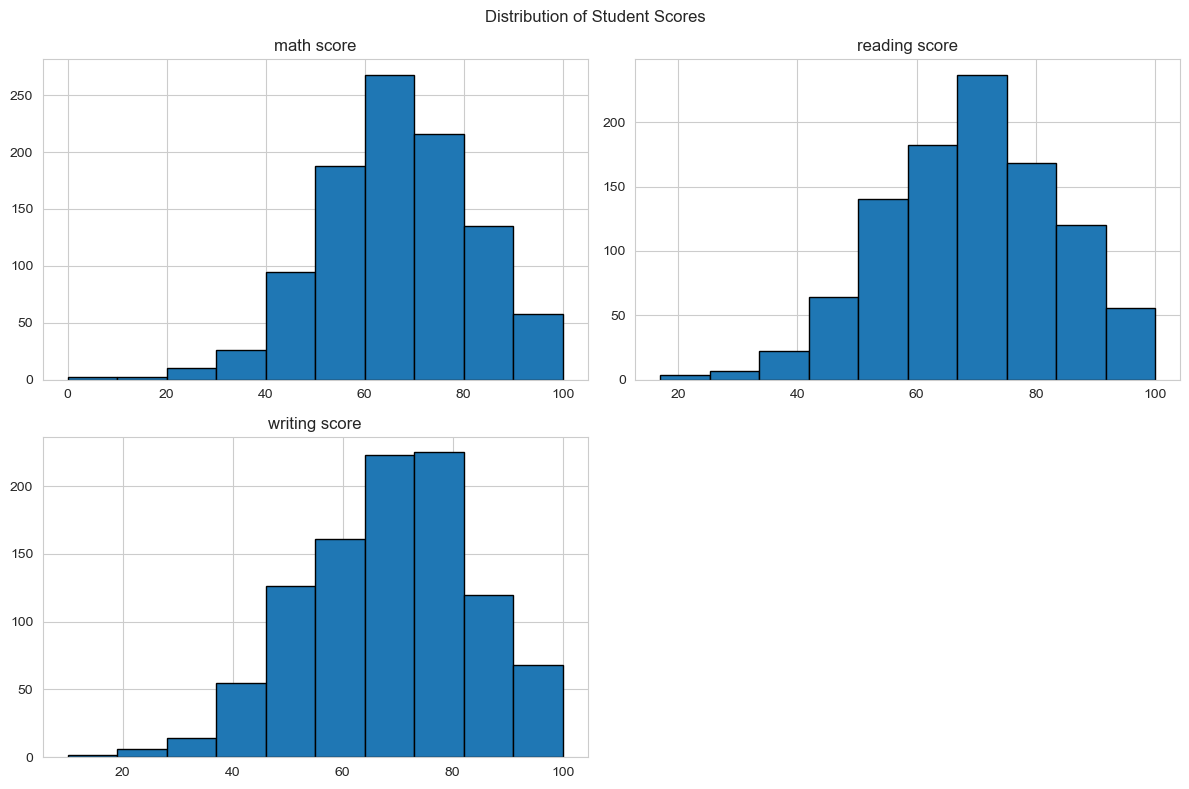

In [42]:
# Histogram
df[score_columns].hist(
    figsize=(12, 8),
    bins=10,
    edgecolor="black"
)

plt.suptitle("Distribution of Student Scores")
plt.tight_layout()
plt.show()


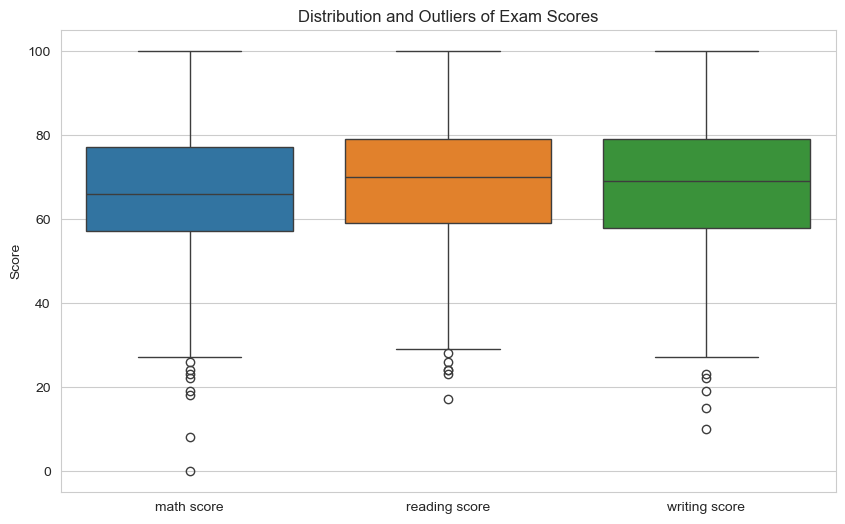

In [43]:
# Box plots
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[score_columns])

plt.title("Distribution and Outliers of Exam Scores")
plt.ylabel("Score")

plt.show()

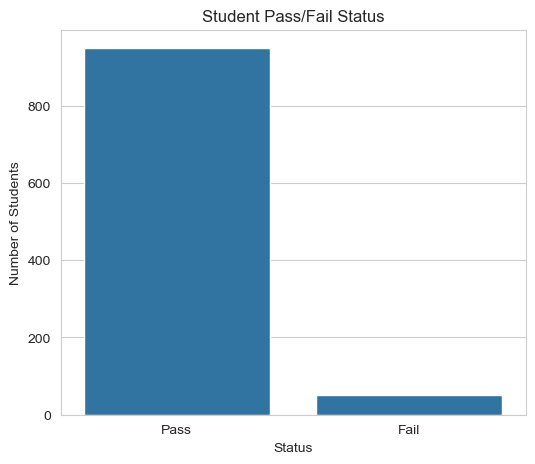

In [44]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x="Pass/Fail Status"
)

plt.title("Student Pass/Fail Status")
plt.xlabel("Status")
plt.ylabel("Number of Students")

plt.show()


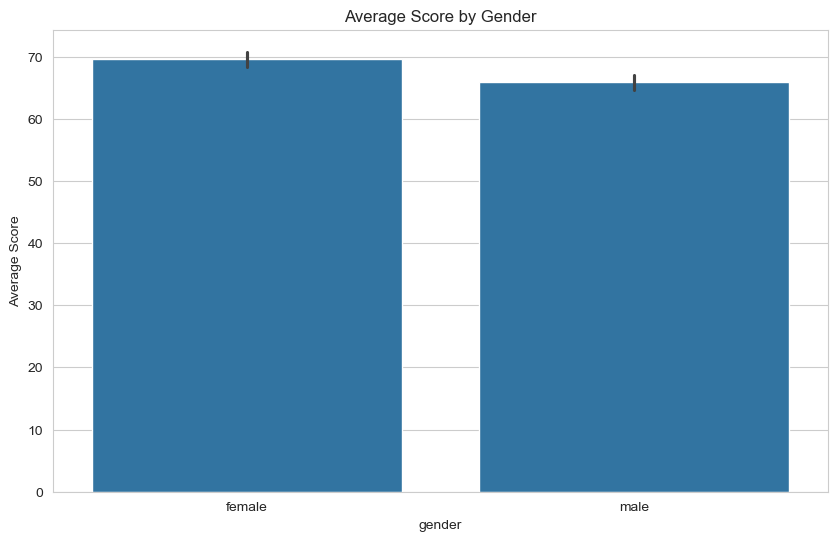

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="gender",
    y="Average Score"
)

plt.title("Average Score by Gender")
plt.show()


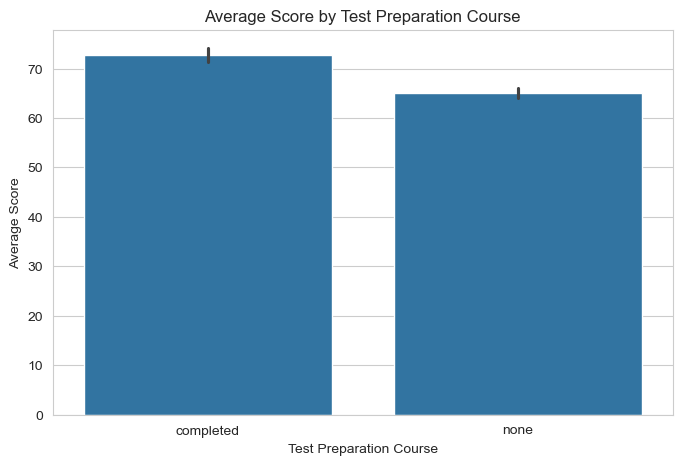

In [46]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="test preparation course",
    y="Average Score"
)

plt.title("Average Score by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")

plt.show()


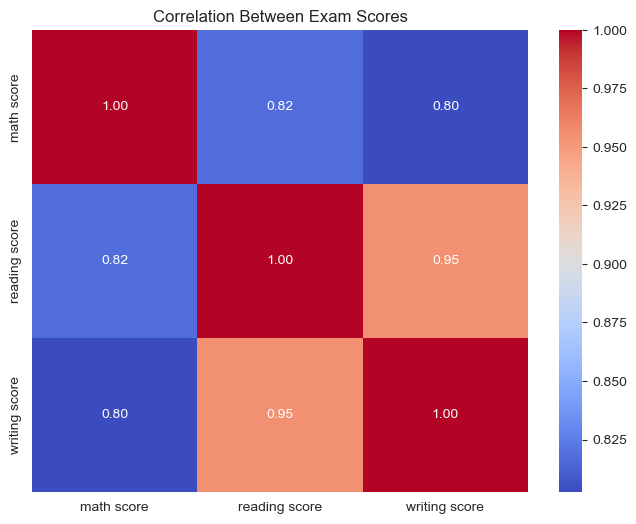

In [47]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Exam Scores")
plt.show()


In [48]:
# Melt data for grouped bar chart
df_melted = df.melt(
    id_vars=['parental level of education', 'lunch'],
    value_vars=['math score', 'reading score', 'writing score'],
    var_name='Subject', value_name='Score'
)

plt.figure(figsize=(12,5))


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

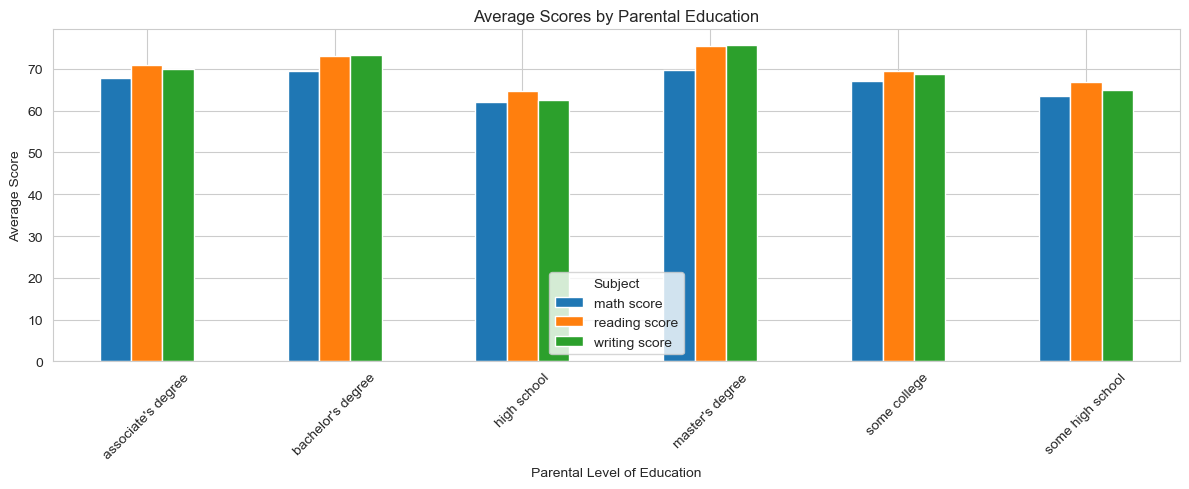

In [49]:
# Grouped Bar Chart - Parental Education
df1 = df.groupby("parental level of education", observed=True)[["math score", "reading score", "writing score"]].mean()

df1.plot(kind="bar", figsize=(12,5))
plt.ylabel("Average Score")
plt.xlabel("Parental Level of Education")
plt.title("Average Scores by Parental Education")
plt.xticks(rotation=45)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

# BUSINESS INSIGHTS

Sure — here are **two-line definitions** for each section:

Overall Performance

Overall performance shows how students perform across Math, Reading, and Writing based on average scores and score variation.

Parental Level of Education

This analyzes how students’ academic performance differs according to their parents’ education level.

Lunch Type

This examines differences in student scores between different lunch categories, such as standard and free/reduced lunch.

Test Preparation

This compares the academic performance of students who completed test preparation with those who did not.

 Gender and Race/Ethnicity

This analyzes how average student scores vary across gender and race/ethnicity groups.

Subject Relationships

This examines the relationships between Math, Reading, and Writing scores using correlations and scatter plots.

 Educational Insights

Educational insights summarize the major performance patterns and identify areas that may need further investigation or academic support.